<a href="https://colab.research.google.com/github/dhritihaldipur/exoplanet-habitability/blob/main/Exoplanet_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import pandas as pd
df = pd.read_csv("/nasa.csv", comment='#')
print(df.shape)


(6375, 84)


In [15]:
cols = ["pl_name", "hostname", "disc_year", "pl_orbper",
        "pl_rade", "pl_bmasse", "pl_eqt", "pl_insol", "st_teff"]
df=df[cols]
print(df.shape)

(6375, 9)


In [16]:
df.isnull().sum()

,0
pl_name,0
hostname,0
disc_year,0
pl_orbper,353
pl_rade,50
pl_bmasse,31
pl_eqt,536
pl_insol,592
st_teff,307


In [17]:
habit=df.dropna(subset=["pl_rade", "pl_eqt", "pl_insol"]).copy()
print(habit.shape)
habit.head()

(5738, 9)


,pl_name,hostname,disc_year,pl_orbper,pl_rade,pl_bmasse,pl_eqt,pl_insol,st_teff
0,11 Com b,11 Com,2007,323.21000,12.2,4914.898486,803.26,68.5387,4874.0
1,11 UMi b,11 UMi,2009,516.21997,12.3,4684.814200,896.43,114.8502,4213.0
2,14 And b,14 And,2008,186.76000,13.1,1131.151301,909.92,115.1634,4888.0
3,14 Her b,14 Her,2002,1766.41000,12.5,2828.672822,147.32,0.0873,5338.0
4,16 Cyg B b,16 Cyg B,1996,798.50000,13.5,565.737400,228.76,0.4540,5750.0


In [18]:
habit.describe()

,disc_year,pl_orbper,pl_rade,pl_bmasse,pl_eqt,pl_insol,st_teff
count,5738.000000,5.680000e+03,5738.000000,5714.000000,5738.000000,5738.000000,5737.000000
mean,2017.016382,7.500635e+04,5.734807,362.866803,836.686152,538.435252,5361.439289
std,5.067411,5.336431e+06,5.327664,1055.898215,495.870380,9962.752351,1242.974979
min,1995.000000,1.768913e-01,0.309800,0.037400,1.480000,0.000000,575.000000
25%,2014.000000,4.301551e+00,1.820250,4.190000,486.000000,10.173450,4908.000000
50%,2016.000000,1.078341e+01,2.810546,8.945000,757.180000,66.792250,5551.000000
75%,2021.000000,3.906633e+01,11.475209,166.781084,1096.750000,284.652750,5905.000000
max,2026.000000,4.020000e+08,77.342100,9534.852210,7777.780000,636352.125800,40000.000000


In [19]:
rocky = habit[(habit['pl_rade']>=0.5)& (habit['pl_rade']<=1.6)].copy()
print(rocky.shape)


(1108, 9)


In [20]:
rocky["insol_diff"] = (rocky["pl_insol"] - 1).abs()
rocky["insol_diff"].head()

,insol_diff
90,5.7600
91,3.7285
92,9.0441
93,1.4456
150,141.7812


In [21]:
top10 = rocky.sort_values("insol_diff").head(10)
top10[["pl_name", "pl_rade", "pl_eqt", "pl_insol"]]

,pl_name,pl_rade,pl_eqt,pl_insol
247,GJ 273 b,1.510,292.47,1.060
6085,Teegarden's Star b,1.050,277.00,1.080
268,GJ 3378 b,1.320,272.00,0.910
4958,LP 890-9 c,1.367,272.00,0.906
4937,L 98-59 f,1.480,285.00,1.100
6070,TRAPPIST-1 d,0.788,286.20,1.115
5996,TOI-700 d,1.145,268.80,0.850
3072,Kepler-1652 b,1.600,268.00,0.810
1916,K2-72 e,1.290,286.34,1.200
3067,Kepler-1649 c,1.060,234.00,0.750


In [22]:
top10[["pl_name", "pl_insol", "insol_diff"]]

,pl_name,pl_insol,insol_diff
247,GJ 273 b,1.060,0.060
6085,Teegarden's Star b,1.080,0.080
268,GJ 3378 b,0.910,0.090
4958,LP 890-9 c,0.906,0.094
4937,L 98-59 f,1.100,0.100
6070,TRAPPIST-1 d,1.115,0.115
5996,TOI-700 d,0.850,0.150
3072,Kepler-1652 b,0.810,0.190
1916,K2-72 e,1.200,0.200
3067,Kepler-1649 c,0.750,0.250


In [23]:
rocky["rade_diff"] = (rocky["pl_rade"] - 1).abs()
rocky["eqt_diff"] = (rocky["pl_eqt"] - 255).abs() / 255
rocky[["pl_name", "rade_diff", "eqt_diff", "insol_diff"]].head()

,pl_name,rade_diff,eqt_diff,insol_diff
90,Barnard b,0.280,0.717647,5.7600
91,Barnard c,0.257,0.568627,3.7285
92,Barnard d,0.306,0.894118,9.0441
93,Barnard e,0.363,0.333333,1.4456
150,DMPP-3 A b,0.440,2.349020,141.7812


In [24]:
for col in ["rade", "eqt", "insol"]:
    rocky[f"{col}_sim"] = 1 / (1 + rocky[f"{col}_diff"])

rocky[["pl_name", "rade_sim", "eqt_sim", "insol_sim"]].head()


,pl_name,rade_sim,eqt_sim,insol_sim
90,Barnard b,0.781250,0.582192,0.147929
91,Barnard c,0.795545,0.637500,0.211484
92,Barnard d,0.765697,0.527950,0.099561
93,Barnard e,0.733676,0.750000,0.408898
150,DMPP-3 A b,0.694444,0.298595,0.007004


In [26]:
rocky["earth_score"] = rocky[["rade_sim", "eqt_sim", "insol_sim"]].mean(axis=1)

rocky.sort_values("earth_score", ascending=False)[["pl_name", "earth_score"]].head(10)

,pl_name,earth_score
6085,Teegarden's Star b,0.932961
5996,TOI-700 d,0.897196
3067,Kepler-1649 c,0.889103
6312,Wolf 1069 b,0.882971
5997,TOI-700 e,0.882293
6071,TRAPPIST-1 e,0.881372
211,GJ 1002 b,0.878802
6070,TRAPPIST-1 d,0.870976
268,GJ 3378 b,0.870836
5187,Proxima Cen b,0.863172


/tmp/ipykernel_709/2582536741.py:19: UserWarning: Glyph 127757 (\N{EARTH GLOBE EUROPE-AFRICA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127757 (\N{EARTH GLOBE EUROPE-AFRICA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


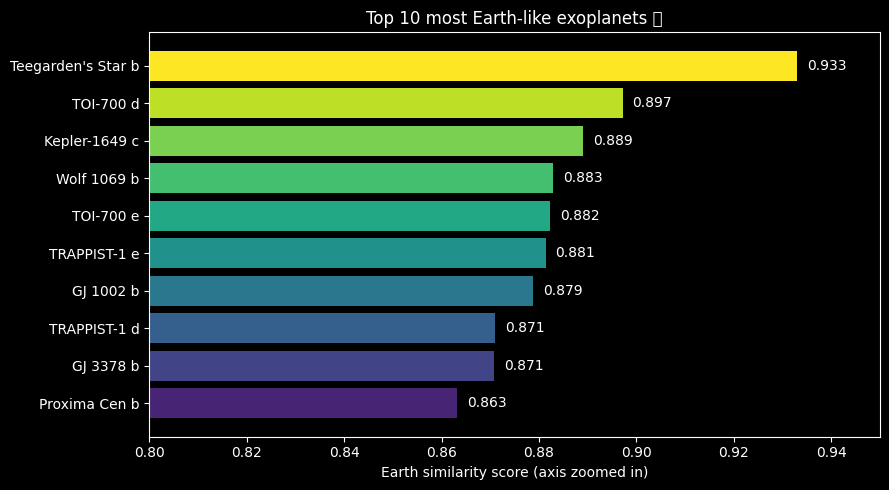

In [28]:
import matplotlib.pyplot as plt

top10 = rocky.sort_values("earth_score", ascending=False).head(10)

plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(top10["pl_name"], top10["earth_score"],
               color=plt.cm.viridis(top10["earth_score"].rank() / 10))
ax.invert_yaxis()
ax.set_xlim(0.8, 0.95)

for bar, score in zip(bars, top10["earth_score"]):
    ax.text(score + 0.002, bar.get_y() + bar.get_height()/2,
            f"{score:.3f}", va="center")

ax.set_xlabel("Earth similarity score (axis zoomed in)")
ax.set_title("Top 10 most Earth-like exoplanets 🌍")
plt.tight_layout()
plt.show()

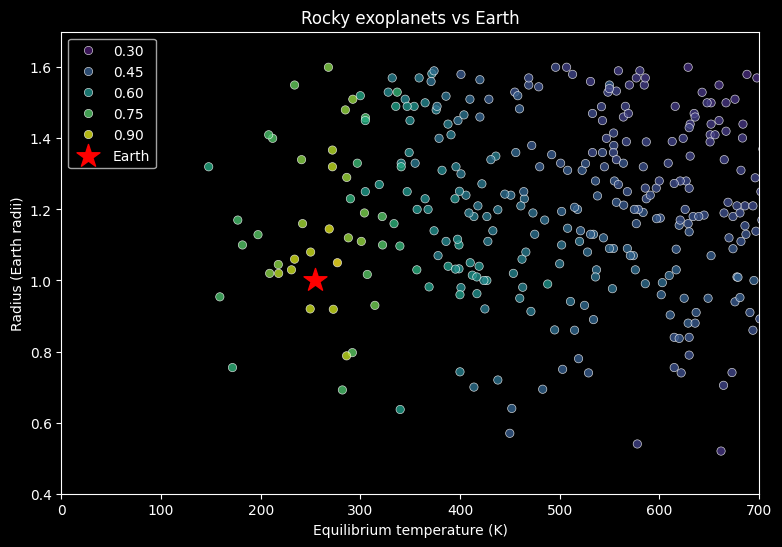

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))
sns.scatterplot(data=rocky, x="pl_eqt", y="pl_rade",
                hue="earth_score", palette="viridis", alpha=0.8)
plt.scatter(255, 1, color="red", marker="*", s=300, label="Earth")
plt.xlabel("Equilibrium temperature (K)")
plt.ylabel("Radius (Earth radii)")
plt.title("Rocky exoplanets vs Earth")
plt.legend()
plt.xlim(0, 700)
plt.ylim(0.4, 1.7)
plt.show()